# Phase 4: Modeling and Analysis

**Question (Phase 1):** on day `d` of a billing month, how accurately can a household's month-end bill be projected,
with a 90% prediction interval, from its smart meter readings? And when should the household get an alert?

The model predicts the kWh still to come (days `d+1` to the end of the month) and adds it to the kWh already on the
meter. The bill is a **computed proxy**: kWh x 14.228 p/kWh (standard tariff, no standing charge), not a real invoice.
Scope is standard-tariff households only (Phase 3 decision). Input: `data/processed/features_day_d.parquet` from
`feature_engineering.ipynb`, one row per household x month x `d`, with `d` in {7, 14, 21}.

Sections: 1 setup, 2 data and time-based split, 3 benchmarks, 4 candidate models and the target transformation,
5 feature selection and tuning, 6 pooled vs per-household, 7 prediction intervals, 8 final test, 9 alert decision
layer, 10 figures, 11 saved output and checks, 12 conclusions.

## 1. Setup

All paths, the tariff, the split dates, tuning grids and thresholds live in this cell. The last block (final `d`,
default X, baseline) holds the decisions taken in section 9; they sit here so later cells have no magic numbers.

In [1]:
from pathlib import Path
import time

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())

# Inputs (read only) and outputs
FEATURES_PARQUET = ROOT / "data/processed/features_day_d.parquet"
PREDICTIONS_PARQUET = ROOT / "data/processed/predictions_test.parquet"
FIG_DIR = ROOT / "reports/figures"

# Problem settings (from Phases 1-3)
TARIFF_GBP_PER_KWH = 0.14228      # 14.228 p/kWh standard tariff; the bill is a computed proxy
D_VALUES = [7, 14, 21]            # candidate forecast days built in Phase 3
ALPHA = 0.10                      # 90% prediction intervals

# Time-based split: (last training month, first validation month, last validation month)
FOLDS = [
    ("2012-12-01", "2013-01-01", "2013-03-01"),
    ("2013-03-01", "2013-04-01", "2013-06-01"),
    ("2013-06-01", "2013-07-01", "2013-09-01"),
]
TEST_START = "2013-10-01"         # Oct 2013 - Jan 2014 is held out until section 8

# Ratio target: remaining kWh divided by the run-rate's remaining kWh
SCALE_FLOOR_KWH_PER_DAY = 0.5     # floor on the to-date daily mean, so near-empty homes don't blow up the ratio
RATIO_CLIP = (0.25, 4.0)          # clip used only for the per-household mean ratio (robust to one odd month)

# Tuning grids
RIDGE_ALPHAS = [0.1, 1, 10, 100, 1000]
HGB_GRID = [
    {"learning_rate": lr, "max_leaf_nodes": leaves, "min_samples_leaf": msl, "max_iter": 300}
    for lr in [0.03, 0.1] for leaves in [7, 31] for msl in [200, 2000]
]
FEATURE_DROP_MIN_GAIN_GBP = 0.05  # drop a feature group if removing it lowers the mean validation MAE by more than this
PERM_SAMPLE_ROWS = 20_000         # rows used for permutation importance
SHRINK_K_GRID = [0, 2, 8, 32, 128]    # per-household model: pseudo-months pulling the household ratio toward 1 (run-rate)
COVERAGE_TOL = 0.03               # an interval method qualifies if every subgroup covers at least 1 - ALPHA - this

# Decision layer
ALERT_X = [0.10, 0.20, 0.30]      # alert if projected bill exceeds baseline by more than X
BASELINES = ["same_month_ly", "trailing_3m", "ly_else_3m"]
# Final decision-layer settings, chosen from the section 9 results (see the takeaway there)
FINAL_D = 14                      # forecast day: half the month left to act, error close to its d = 21 level
ALERT_DEFAULT_X = 0.20            # default threshold; a household setting, not something the data can pick
ALERT_BASELINE = "ly_else_3m"     # same month last year, else the trailing 3-month mean

BOOT_REPS = 1000                  # household-block bootstrap resamples
RANDOM_STATE = 42
FIG_DPI = 200
FIG_DIR.mkdir(parents=True, exist_ok=True)

con = duckdb.connect()
con.sql("SET enable_progress_bar = false")

Every figure uses the Phase 3 look (fixed colour order, light grid) and is saved to `reports/figures/`.

In [2]:
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8b5cf6"]
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.prop_cycle": plt.cycler(color=COLORS),
    "font.size": 10, "axes.titlesize": 11, "lines.linewidth": 2,
})


def save(fig, name):
    """Save a figure to reports/figures/ and show it."""
    fig.savefig(FIG_DIR / name, dpi=FIG_DPI, bbox_inches="tight")
    plt.show()
    print("Saved", (FIG_DIR / name).relative_to(ROOT))

## 2. Data and time-based split

Each row gets `scale_kwh`, what the run-rate expects for the rest of the month (to-date daily mean x days left). It is
used in section 4 for the ratio target and in section 7 for the scaled intervals. The daily mean is floored at
0.5 kWh/day so a near-empty home does not produce a huge ratio.

In [3]:
df = con.sql(f"""
    SELECT *,
           -- what the run-rate expects for the rest of the month, floored for near-empty homes
           greatest(daily_mean_to_date, {SCALE_FLOOR_KWH_PER_DAY}) * days_remaining AS scale_kwh
    FROM read_parquet('{FEATURES_PARQUET}')
    ORDER BY month, LCLid, d
""").df()
df["month"] = pd.to_datetime(df["month"])
df["ratio"] = df["remaining_kwh"] / df["scale_kwh"]
df["known_gbp"] = df["kwh_to_date"] * TARIFF_GBP_PER_KWH   # the part of the bill already fixed on day d
df["scale_gbp"] = df["scale_kwh"] * TARIFF_GBP_PER_KWH

assert not df.duplicated(["LCLid", "month", "d"]).any()
print(f"{len(df):,} rows, {df.LCLid.nunique():,} households, "
      f"{df.month.min():%b %Y} to {df.month.max():%b %Y}, d in {sorted(int(x) for x in df.d.unique())}")
print(f"Rows where the to-date daily mean is below the {SCALE_FLOOR_KWH_PER_DAY} kWh floor: "
      f"{(df.daily_mean_to_date < SCALE_FLOOR_KWH_PER_DAY).sum():,}")

254,421 rows, 4,428 households, Dec 2011 to Jan 2014, d in [7, 14, 21]
Rows where the to-date daily mean is below the 0.5 kWh floor: 415


The split is by **month**, never by row, so the three `d` rows of a household-month always fall in the same part and
no future month is used to predict a past one. Three expanding-window folds are used for every choice (features,
hyperparameters, interval method). Oct 2013 to Jan 2014 is the test set and is not touched until section 8.

| Part | Training months | Evaluated on |
|---|---|---|
| Fold 1 | Dec 2011 - Dec 2012 | Jan - Mar 2013 |
| Fold 2 | Dec 2011 - Mar 2013 | Apr - Jun 2013 |
| Fold 3 | Dec 2011 - Jun 2013 | Jul - Sep 2013 |
| Test | Dec 2011 - Sep 2013 | Oct 2013 - Jan 2014 |

Lag availability matters: most households joined in mid-2012, so same-month-last-year values barely exist before 2013.

In [4]:
def partition(month):
    """Name the split a month belongs to (validation folds overlap with later training sets)."""
    if month >= pd.Timestamp(TEST_START):
        return "test"
    for i, (_, v0, v1) in enumerate(FOLDS, 1):
        if pd.Timestamp(v0) <= month <= pd.Timestamp(v1):
            return f"fold {i} validation"
    return "train only"


month_part = {m: partition(m) for m in df.month.unique()}
df["partition"] = df.month.map(month_part)
lag_cols = ["previous_month_kwh", "rolling_3month_kwh", "same_month_last_year_kwh"]
split_table = (df.groupby("partition", sort=False)
                 .agg(first_month=("month", "min"), last_month=("month", "max"), rows=("d", "size"),
                      households=("LCLid", "nunique"),
                      **{f"has_{c.removesuffix('_kwh')}": (c, lambda s: s.notna().mean()) for c in lag_cols}))
split_table


def fold_masks(i):
    """Train and validation masks for fold i (1-based). Training is every month up to the fold's cut-off."""
    t_end, v0, v1 = (pd.Timestamp(x) for x in FOLDS[i - 1])
    return (df.month <= t_end).to_numpy(), df.month.between(v0, v1).to_numpy()


test_mask = (df.month >= pd.Timestamp(TEST_START)).to_numpy()
final_train_mask = ~test_mask
print(split_table.to_string(float_format="{:.3f}".format))

                  first_month last_month   rows  households  has_previous_month  has_rolling_3month  has_same_month_last_year
partition                                                                                                                    
train only         2011-12-01 2012-12-01  92247        4410               0.854               0.580                     0.002
fold 1 validation  2013-01-01 2013-03-01  38676        4356               0.996               0.957                     0.116
fold 2 validation  2013-04-01 2013-06-01  37983        4258               0.997               0.993                     0.420
fold 3 validation  2013-07-01 2013-09-01  37194        4183               0.997               0.993                     0.817
test               2013-10-01 2014-01-01  48321        4118               0.996               0.989                     0.967


**Takeaway.** 254,421 rows from 4,428 households. Each validation fold holds about 37,000-39,000 rows and the test
set 48,321. Same-month-last-year values exist for only 0.2% of the rows used to train fold 1 but for 97% of test
rows, so any model that leans on that feature learns it from little data.

## 3. Benchmarks

Phase 1 named three benchmarks. They need no training, so they are scored directly on each fold's validation months:

- **Run-rate:** the to-date daily mean x days in the month.
- **Last month:** last month's full bill.
- **Same month last year:** that month's bill one year earlier.

A chain (same month last year, else last month, else run-rate) gives every row a forecast. The lag benchmarks only
exist for some rows, so each is also compared with the run-rate on exactly the same rows.

In [5]:
def bill_metrics(actual, pred):
    """Point-forecast metrics on the bill, in GBP. Bias > 0 means the forecast is too high."""
    actual, pred = np.asarray(actual), np.asarray(pred)
    err = pred - actual
    return {"MAE": np.mean(np.abs(err)), "RMSE": np.sqrt(np.mean(err ** 2)),
            "MdAPE %": 100 * np.median(np.abs(err) / actual), "bias": np.mean(err)}


BENCHMARKS = {
    "Run-rate": df["runrate_bill_gbp"],
    "Last month": df["last_month_bill_gbp"],
    "Same month last year": df["same_month_ly_bill_gbp"],
    "Chain (LY, else last month, else run-rate)":
        df["same_month_ly_bill_gbp"].fillna(df["last_month_bill_gbp"]).fillna(df["runrate_bill_gbp"]),
}

rows = []
for i in range(1, len(FOLDS) + 1):
    _, val = fold_masks(i)
    for name, pred in BENCHMARKS.items():
        ok = val & pred.notna().to_numpy()
        rows.append({"fold": i, "benchmark": name, "available %": 100 * ok.sum() / val.sum(),
                     **bill_metrics(df.final_bill_gbp[ok], pred[ok]),
                     "run-rate MAE, same rows": bill_metrics(df.final_bill_gbp[ok], df.runrate_bill_gbp[ok])["MAE"]})
bench_folds = pd.DataFrame(rows)
bench_summary = bench_folds.groupby("benchmark", sort=False).mean(numeric_only=True).drop(columns="fold")
print(bench_summary.round(2).to_string())

                                            available %   MAE   RMSE  MdAPE %  bias  run-rate MAE, same rows
benchmark                                                                                                   
Run-rate                                         100.00  3.43   7.72     4.08 -0.18                     3.43
Last month                                        99.70  6.83  13.29    10.13  1.97                     3.42
Same month last year                              45.11  8.85  17.48    11.87 -1.30                     3.45
Chain (LY, else last month, else run-rate)       100.00  7.27  13.91    11.04  1.57                     3.43


**Takeaway.** The run-rate is the benchmark to beat: mean validation MAE GBP 3.43, half that of last month (GBP 6.83)
and well under same month last year (GBP 8.85, available on 45% of rows). On the same rows the run-rate also scores
about GBP 3.43, so the lag benchmarks lose because of what they ignore, not because of which rows they cover: they
predict the whole month and throw away the `d` days already on the meter. They stay as reference points; the run-rate
is the one each model must beat.

## 4. Candidate models and the target transformation

**Why these models.** This is regression on about 250,000 rows with a mix of size, calendar and lag features.

- **Ridge regression** is the interpretable linear reference. Median imputation, missing-value indicators and
  scaling sit inside the pipeline, so they are fitted on each fold's training months only (Phase 2 deferred scaling
  to here for that reason).
- **Histogram gradient boosting** (scikit-learn) learns non-linear effects and interactions, such as "early in the
  month and a big household", handles missing lags natively, and trains in seconds at this size. Its built-in early
  stopping is switched off because it holds out a *random* 10% of rows, which would break the time split.

`days_elapsed` is left out because it equals `d`.

**Target transformation.** Errors grow with household size: a 5% miss is GBP 1 for a small home and GBP 10 for a large
one. Instead of learning `remaining_kwh` directly, the ratio model learns
`ratio = remaining_kwh / scale_kwh`, the factor by which the rest of the month will differ from the run-rate. A ratio
of 1 is the run-rate itself, so the model only has to learn the correction. It is trained with an absolute-error loss
weighted by `scale_kwh`, which makes the loss exactly the absolute error in kWh, and therefore in GBP.

The relative features follow the same idea: the last 7 days against the to-date mean, and each earlier-month value
against the run-rate.

In [6]:
BASE_FEATURES = [
    "d", "days_remaining", "kwh_to_date", "daily_mean_to_date", "last7_mean_kwh", "run_rate_kwh",
    "previous_month_kwh", "rolling_3month_kwh", "same_month_last_year_kwh",
    "month_sin", "month_cos", "weekend_days_remaining", "holidays_remaining", "temp_mean_to_date",
    "acorn_comfortable", "acorn_adversity", "acorn_unknown",
]
# Relative versions of the size features: how this month compares with the household's own level
df["last7_vs_mean"] = df["last7_mean_kwh"] / df["daily_mean_to_date"].clip(lower=SCALE_FLOOR_KWH_PER_DAY)
floored_run_rate = df["daily_mean_to_date"].clip(lower=SCALE_FLOOR_KWH_PER_DAY) * (df["d"] + df["days_remaining"])
for c in lag_cols:
    df[f"{c.removesuffix('_kwh')}_vs_runrate"] = df[c] / floored_run_rate
REL_FEATURES = ["last7_vs_mean", "previous_month_vs_runrate", "rolling_3month_vs_runrate",
                "same_month_last_year_vs_runrate"]


class BillModel:
    """Predicts the remaining kWh for days d+1..end and turns it into a month-end bill.

    target='raw':   learn remaining_kwh directly.
    target='ratio': learn remaining_kwh / scale_kwh (a correction factor on the run-rate), weighted by scale_kwh,
                    so an absolute-error loss on the ratio equals an absolute-error loss in kWh.
    """

    def __init__(self, estimator, target, features):
        self.estimator, self.target, self.features = estimator, target, features

    def fit(self, data):
        est = clone(self.estimator)
        X = data[self.features]
        if self.target == "raw":
            est.fit(X, data["remaining_kwh"])
        else:
            last = est.steps[-1][0] if hasattr(est, "steps") else None
            kw = {f"{last}__sample_weight": data["scale_kwh"]} if last else {"sample_weight": data["scale_kwh"]}
            est.fit(X, data["ratio"], **kw)
        self.fitted_ = est
        return self

    def predict_remaining(self, data):
        p = self.fitted_.predict(data[self.features])
        if self.target == "ratio":
            p = p * data["scale_kwh"].to_numpy()
        return np.clip(p, 0, None)        # remaining usage cannot be negative

    def predict_bill(self, data):
        return (data["kwh_to_date"].to_numpy() + self.predict_remaining(data)) * TARIFF_GBP_PER_KWH


def ridge(alpha):
    return make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(), Ridge(alpha=alpha))


def hgb(loss="absolute_error", **params):
    # early_stopping=False: the built-in early stopping holds out a *random* 10% of rows, which would mix months
    # (and the three d rows of one household-month) across train and validation
    params = {"learning_rate": 0.1, "max_leaf_nodes": 31, "min_samples_leaf": 20, "max_iter": 300} | params
    return HistGradientBoostingRegressor(loss=loss, early_stopping=False, random_state=RANDOM_STATE, **params)


def cv_score(model, folds=range(1, len(FOLDS) + 1), keep_oof=False):
    """Fit on each fold's training months, score on its validation months. Returns per-fold metrics (+ OOF)."""
    out, oof = [], np.full(len(df), np.nan)
    for i in folds:
        tr, va = fold_masks(i)
        m = model.fit(df[tr])
        pred = m.predict_bill(df[va])
        oof[va] = pred
        out.append({"fold": i, **bill_metrics(df.final_bill_gbp[va], pred)})
    res = pd.DataFrame(out)
    return (res, oof) if keep_oof else res

In [7]:
t0 = time.time()
candidates = {
    "Ridge, raw kWh target": BillModel(ridge(1.0), "raw", BASE_FEATURES),
    "Gradient boosting, raw kWh, squared loss": BillModel(hgb("squared_error"), "raw", BASE_FEATURES),
    "Gradient boosting, raw kWh, absolute loss": BillModel(hgb(), "raw", BASE_FEATURES),
    "Gradient boosting, ratio target": BillModel(hgb(), "ratio", BASE_FEATURES),
}
cand_folds = pd.concat([cv_score(m).assign(model=n) for n, m in candidates.items()])
runrate_folds = bench_folds[bench_folds.benchmark == "Run-rate"].assign(model="Run-rate benchmark")
cand_summary = (pd.concat([runrate_folds, cand_folds]).groupby("model", sort=False)
                  [["MAE", "RMSE", "MdAPE %", "bias"]].mean())
print(cand_summary.round(3).to_string())
print(cand_folds.pivot(index="model", columns="fold", values="MAE").round(3).to_string())
print(f"{time.time() - t0:.0f}s")

                                             MAE   RMSE  MdAPE %   bias
model                                                                  
Run-rate benchmark                         3.425  7.721    4.082 -0.176
Ridge, raw kWh target                      3.806  7.692    6.258  0.169
Gradient boosting, raw kWh, squared loss   3.608  7.890    4.647 -0.443
Gradient boosting, raw kWh, absolute loss  3.492  7.808    4.424 -0.357
Gradient boosting, ratio target            3.487  7.514    4.433 -0.615
fold                                           1      2      3
model                                                         
Gradient boosting, ratio target            4.524  3.424  2.514
Gradient boosting, raw kWh, absolute loss  4.426  3.520  2.529
Gradient boosting, raw kWh, squared loss   4.470  3.745  2.609
Ridge, raw kWh target                      4.577  3.757  3.084
28s


**Takeaway.** With default settings no model beats the run-rate yet (GBP 3.43). Ridge is worst (GBP 3.81).
Among the gradient boosting variants, the absolute-error loss beats the squared loss (GBP 3.49 vs 3.61), because the
squared loss chases a few very large months. The ratio target matches the raw target on MAE (GBP 3.49) and has the
lowest RMSE (7.51). Every model does worst on fold 1, which is trained on 2012 alone. The ratio target is kept for
two reasons: its RMSE is lowest, and it makes the scaled intervals in section 7 natural.

## 5. Feature selection and tuning

**Feature groups.** Each group is dropped in turn, and a group goes if dropping it lowers the mean validation MAE
by more than GBP 0.05 (`FEATURE_DROP_MIN_GAIN_GBP`). Groups are tested together because related features stand in for
each other, so dropping one at a time understates their value.

In [8]:
FEATURE_GROUPS = {
    "month of year (sin/cos)": ["month_sin", "month_cos"],
    "temperature to date": ["temp_mean_to_date"],
    "earlier-month lags": lag_cols,
    "relative features": REL_FEATURES,
    "ACORN group": ["acorn_comfortable", "acorn_adversity", "acorn_unknown"],
    "rest-of-month calendar": ["weekend_days_remaining", "holidays_remaining"],
}
ALL_FEATURES = BASE_FEATURES + REL_FEATURES
t0 = time.time()
full = cv_score(BillModel(hgb(), "ratio", ALL_FEATURES))
abl_rows = [{"dropped": "(none)", **{f"MAE fold {i}": m for i, m in zip(full.fold, full.MAE)}, "MAE mean": full.MAE.mean()}]
for g, cols in FEATURE_GROUPS.items():
    res = cv_score(BillModel(hgb(), "ratio", [f for f in ALL_FEATURES if f not in cols]))
    abl_rows.append({"dropped": g, **{f"MAE fold {i}": m for i, m in zip(res.fold, res.MAE)}, "MAE mean": res.MAE.mean()})
ablation = pd.DataFrame(abl_rows)
ablation["change vs full"] = ablation["MAE mean"] - full.MAE.mean()

dropped_groups = ablation.loc[ablation["change vs full"] < -FEATURE_DROP_MIN_GAIN_GBP, "dropped"].tolist()
FEATURES = [f for f in ALL_FEATURES if not any(f in FEATURE_GROUPS[g] for g in dropped_groups)]
print(ablation.round(3).to_string(index=False))
print(f"Dropped groups: {dropped_groups}; {len(FEATURES)} features kept ({time.time() - t0:.0f}s)")

                dropped  MAE fold 1  MAE fold 2  MAE fold 3  MAE mean  change vs full
                 (none)       4.473       3.412       2.463     3.449           0.000
month of year (sin/cos)       3.849       3.576       2.511     3.312          -0.137
    temperature to date       4.511       3.393       2.446     3.450           0.001
     earlier-month lags       4.377       3.368       2.465     3.404          -0.046
      relative features       4.524       3.424       2.514     3.487           0.038
            ACORN group       4.478       3.394       2.462     3.445          -0.005
 rest-of-month calendar       4.498       3.790       2.464     3.584           0.135
Dropped groups: ['month of year (sin/cos)']; 19 features kept (160s)


**Takeaway.** Dropping the month-of-year pair (sin/cos) lowers the mean MAE by GBP 0.14, almost all in fold 1
(4.47 to 3.85). With one or two years of history, the model learns each calendar month from one or two examples, so
it learns that year's weather, not a seasonal pattern. The pair is dropped. The remaining
groups either help (relative features, rest-of-month calendar) or change MAE by less than the GBP 0.05 rule.

**Hyperparameters.** Ridge alpha and a small gradient boosting grid (learning rate, tree size, minimum leaf size),
scored by mean MAE in GBP across the three folds, using the kept features.

In [9]:
t0 = time.time()
ridge_rows = [cv_score(BillModel(ridge(a), "raw", FEATURES)).assign(alpha=a) for a in RIDGE_ALPHAS]
ridge_tuning = pd.concat(ridge_rows).groupby("alpha")[["MAE", "RMSE"]].agg(["mean", "std"])
BEST_RIDGE_ALPHA = float(ridge_tuning[("MAE", "mean")].idxmin())
print(ridge_tuning.round(3).to_string())
print("Best ridge alpha:", BEST_RIDGE_ALPHA)

hgb_rows = []
for k, params in enumerate(HGB_GRID, 1):
    res = cv_score(BillModel(hgb(**params), "ratio", FEATURES))
    hgb_rows.append({"config": k, **params, **{f"MAE fold {i}": m for i, m in zip(res.fold, res.MAE)},
                     "MAE mean": res.MAE.mean(), "RMSE mean": res.RMSE.mean()})
hgb_tuning = pd.DataFrame(hgb_rows).sort_values("MAE mean")
best = hgb_tuning.iloc[0]
BEST_HGB = {"learning_rate": float(best.learning_rate), "max_leaf_nodes": int(best.max_leaf_nodes),
            "min_samples_leaf": int(best.min_samples_leaf), "max_iter": int(best.max_iter)}
print(hgb_tuning.round(3).to_string(index=False))
print("Best gradient boosting settings:", BEST_HGB, f"({time.time() - t0:.0f}s)")

          MAE          RMSE       
         mean    std   mean    std
alpha                             
0.1     3.703  0.871  7.795  2.229
1.0     3.698  0.865  7.789  2.224
10.0    3.675  0.841  7.760  2.196
100.0   3.677  0.839  7.742  2.184
1000.0  3.797  0.914  7.786  2.235
Best ridge alpha: 10.0


 config  learning_rate  max_leaf_nodes  min_samples_leaf  max_iter  MAE fold 1  MAE fold 2  MAE fold 3  MAE mean  RMSE mean
      3           0.03              31               200       300       3.783       3.544       2.488     3.271      7.297
      4           0.03              31              2000       300       3.773       3.594       2.492     3.286      7.282
      5           0.10               7               200       300       3.727       3.647       2.506     3.293      7.279
      8           0.10              31              2000       300       3.805       3.596       2.490     3.297      7.296
      7           0.10              31               200       300       3.804       3.595       2.498     3.299      7.299
      1           0.03               7               200       300       3.710       3.659       2.530     3.300      7.293
      2           0.03               7              2000       300       3.721       3.684       2.535     3.313      7.330
      6 

**Takeaway.** Ridge does best at alpha = 10 (GBP 3.68). Gradient boosting does best with a learning rate of 0.03,
31-leaf trees and at least 200 rows per leaf (GBP 3.27). The top five settings are within GBP 0.03 of each other, so
the result does not hinge on the exact choice.

**Permutation importance** on fold 3 (20,000 sampled rows): how much the bill MAE rises when one feature is shuffled.

In [10]:
tr, va = fold_masks(len(FOLDS))
m_last = BillModel(hgb(**BEST_HGB), "ratio", FEATURES).fit(df[tr])
sub = df[va].sample(PERM_SAMPLE_ROWS, random_state=RANDOM_STATE)
pi = permutation_importance(m_last.fitted_, sub[FEATURES], sub["ratio"], sample_weight=sub["scale_kwh"],
                            scoring="neg_mean_absolute_error", n_repeats=5, random_state=RANDOM_STATE)
# A weighted MAE on the ratio equals the MAE in kWh divided by the mean scale; convert back to GBP per bill
to_gbp = sub["scale_kwh"].mean() * TARIFF_GBP_PER_KWH
importance = (pd.DataFrame({"feature": FEATURES, "MAE increase (GBP)": pi.importances_mean * to_gbp,
                            "sd": pi.importances_std * to_gbp})
                .sort_values("MAE increase (GBP)", ascending=False).reset_index(drop=True))
print(importance.round(4).to_string(index=False))

                        feature  MAE increase (GBP)     sd
      previous_month_vs_runrate              0.2388 0.0113
                  last7_vs_mean              0.1530 0.0065
same_month_last_year_vs_runrate              0.0658 0.0019
      rolling_3month_vs_runrate              0.0473 0.0035
                    kwh_to_date              0.0130 0.0020
                 days_remaining              0.0122 0.0025
             holidays_remaining              0.0098 0.0019
       same_month_last_year_kwh              0.0031 0.0005
                   run_rate_kwh              0.0017 0.0004
             rolling_3month_kwh              0.0010 0.0004
             daily_mean_to_date              0.0010 0.0007
                acorn_adversity              0.0006 0.0003
                 last7_mean_kwh              0.0006 0.0003
              acorn_comfortable              0.0002 0.0001
                  acorn_unknown              0.0000 0.0000
             previous_month_kwh             -0.0011 0.00

**Takeaway.** The model relies mostly on the relative features. Most important is last month against the current
run-rate, then the last 7 days against the to-date mean. Both say "this household is running above or below its usual
level". Raw size features add almost nothing once the ratio target removes household size. Temperature to date and
weekend days remaining have slightly negative scores (shuffling them helps a little), but the group test in 5.1 found
the change too small to drop them.

**Tuned models vs the run-rate, per fold.** The out-of-fold forecasts are kept for section 7.

In [11]:
MODELS = {
    "Ridge": BillModel(ridge(BEST_RIDGE_ALPHA), "raw", FEATURES),
    "Gradient boosting": BillModel(hgb(**BEST_HGB), "ratio", FEATURES),
}
oof = {"Run-rate": df["runrate_bill_gbp"].to_numpy()}   # needs no fitting
val_rows = []
for name, m in MODELS.items():
    res, oof[name] = cv_score(m, keep_oof=True)
    val_rows.append(res.assign(model=name))
val_rows.append(bench_folds[bench_folds.benchmark == "Run-rate"].assign(model="Run-rate"))
val_compare = pd.concat(val_rows)
print(val_compare.pivot(index="model", columns="fold", values="MAE").round(3).to_string())

fold                   1      2      3
model                                 
Gradient boosting  3.783  3.544  2.488
Ridge              4.259  4.055  2.711
Run-rate           3.928  3.646  2.702


**Takeaway.** Tuned gradient boosting beats the run-rate in **every** fold: GBP 3.78 vs 3.93, 3.54 vs 3.65 and
2.49 vs 2.70. Ridge loses to the run-rate in all three folds, so the linear model is kept only as a reference.

## 6. Pooled vs per-household models (secondary question)

A separate regression per household is not realistic here: a household has a median of about 20 months, so about 20
rows per `d`. The per-household model is therefore the household's own average ratio at the same `d` over its
*earlier* months only, shrunk toward 1 (the run-rate) with weight k / (n + k), where n is the number of earlier
months. k = 0 trusts the household's history fully; a large k falls back to the run-rate.

A middle option adds that household history to the pooled model as two extra features.

In [12]:
# For each row: the household's mean ratio at the same d over its *earlier* months only (rows are sorted by month)
clipped = df["ratio"].clip(*RATIO_CLIP)
grp = clipped.groupby([df["LCLid"], df["d"]])
df["hh_n_months"] = grp.cumcount()
df["hh_ratio_mean"] = (grp.cumsum() - clipped) / df["hh_n_months"].replace(0, np.nan)
assert (df.groupby(["LCLid", "d"]).month.diff().dropna() > pd.Timedelta(0)).all(), "rows must be in month order"


def per_household_bill(k):
    """Household's own past ratio, shrunk toward 1 (the run-rate) with weight k / (n + k)."""
    n = df["hh_n_months"]
    r = (n * df["hh_ratio_mean"].fillna(1.0) + k * 1.0) / (n + k).replace(0, np.nan)
    return ((df["kwh_to_date"] + r.fillna(1.0) * df["scale_kwh"]) * TARIFF_GBP_PER_KWH).to_numpy()


hh_rows = []
for k in SHRINK_K_GRID:
    pred = per_household_bill(k)
    for i in range(1, len(FOLDS) + 1):
        _, va = fold_masks(i)
        hh_rows.append({"model": f"Per-household, k = {k}", "fold": i,
                        **bill_metrics(df.final_bill_gbp[va], pred[va])})
HH_FEATURES = FEATURES + ["hh_ratio_mean", "hh_n_months"]
res = cv_score(BillModel(hgb(**BEST_HGB), "ratio", HH_FEATURES))
hh_rows += res.assign(model="Pooled + household history features").to_dict("records")
pooled_vs_hh = pd.concat([pd.DataFrame(hh_rows), val_compare[val_compare.model.isin(["Gradient boosting", "Run-rate"])]
                            .replace({"Gradient boosting": "Pooled gradient boosting", "Run-rate": "Run-rate (k = infinity)"})])
pooled_vs_hh_table = pooled_vs_hh.pivot_table(index="model", columns="fold", values="MAE", sort=False)
pooled_vs_hh_table["mean"] = pooled_vs_hh_table.mean(axis=1)
print(pooled_vs_hh_table.round(3).to_string())

fold                                     1      2      3   mean
model                                                          
Per-household, k = 0                 4.510  4.270  2.969  3.917
Per-household, k = 2                 4.262  4.128  2.911  3.767
Per-household, k = 8                 4.043  3.928  2.820  3.597
Per-household, k = 32                3.934  3.747  2.735  3.472
Per-household, k = 128               3.923  3.672  2.708  3.434
Pooled + household history features  3.771  3.720  2.481  3.324
Pooled gradient boosting             3.783  3.544  2.488  3.271
Run-rate (k = infinity)              3.928  3.646  2.702  3.425


**Takeaway.** The per-household model gets *better* as it trusts the household *less*: GBP 3.92 at k = 0 down to
3.43 at k = 128, which is the run-rate (3.43). A household's past ratio of "rest of month vs first `d` days" does not
carry over to the next month; it is mostly noise. Adding household history to the pooled model also makes it worse
(GBP 3.32 vs 3.27). **Answer to the secondary question: the pooled model wins.** What it learns ("households
that ran high last month and in the last week tend to keep running high") is shared across households, and 20 months
per household is too few to learn it separately.

## 7. Prediction intervals

Three ways to build a 90% interval around the gradient boosting forecast, all split-conformal and calibrated
separately for each `d`:

- **absolute:** forecast +/- a fixed GBP amount (the 90th percentile of past absolute errors).
- **scaled:** forecast +/- q x `scale_gbp`, so the width grows with the household's usage and with the days left.
- **cqr** (conformalized quantile regression): two extra gradient boosting models predict the 5th and 95th
  percentiles, then a conformal correction widens or narrows them to hit 90% on past data.

No interval falls below the bill already on the meter at day `d`.

Calibration uses **out-of-fold errors**: each fold's validation forecasts come from a model that never saw those
months. To choose the method, calibrate on folds 1-2 and check on fold 3. The method must cover at least 87%
(90% - `COVERAGE_TOL`) in every subgroup (by `d`, month and household size); the narrowest one that does is chosen.

Conformal coverage is guaranteed only when errors are exchangeable over time, which seasonal data is not, so coverage
is checked empirically rather than assumed.

In [13]:
t0 = time.time()
Q_LO, Q_HI = ALPHA / 2, 1 - ALPHA / 2
QUANTILE_MODELS = {q: BillModel(hgb("quantile", quantile=q, **BEST_HGB), "ratio", FEATURES) for q in (Q_LO, Q_HI)}
oof_q = {}
for q, m in QUANTILE_MODELS.items():
    _, oof_q[q] = cv_score(m, keep_oof=True)
print(f"Quantile models fitted on 3 folds ({time.time() - t0:.0f}s)")


def conformal_q(scores):
    """Split-conformal quantile: the ceil((n+1)(1-alpha))-th smallest score."""
    n = len(scores)
    return np.quantile(scores, min(1.0, np.ceil((n + 1) * (1 - ALPHA)) / n), method="higher")


def interval_scores(method, y, point, lo, hi, scale):
    if method == "absolute":
        return np.abs(y - point)
    if method == "scaled":
        return np.abs(y - point) / scale
    return np.maximum(lo - y, y - hi)                       # CQR


def apply_interval(method, q, point, lo, hi, scale, known):
    if method == "absolute":
        lower, upper = point - q, point + q
    elif method == "scaled":
        lower, upper = point - q * scale, point + q * scale
    else:
        lower, upper = lo - q, hi + q
    # the bill cannot end below what is already on the meter at day d
    return np.maximum(lower, known), np.maximum(upper, known)


INTERVAL_METHODS = ["absolute", "scaled", "cqr"]


def calibrate_and_apply(cal_mask, eval_mask, point_cal, point_eval, lo_cal, hi_cal, lo_eval, hi_eval):
    """Per-d conformal calibration on cal_mask rows, applied to eval_mask rows. Returns {method: (lower, upper)}."""
    y = df["final_bill_gbp"].to_numpy()
    scale, known, d = df["scale_gbp"].to_numpy(), df["known_gbp"].to_numpy(), df["d"].to_numpy()
    out = {}
    for method in INTERVAL_METHODS:
        lower, upper = np.full(eval_mask.sum(), np.nan), np.full(eval_mask.sum(), np.nan)
        for dv in D_VALUES:
            c, e = cal_mask & (d == dv), (d[eval_mask] == dv)
            s = interval_scores(method, y[c], point_cal[c], lo_cal[c], hi_cal[c], scale[c])
            q = conformal_q(s)
            ev = np.flatnonzero(eval_mask)[e]
            lower[e], upper[e] = apply_interval(method, q, point_eval[e], lo_eval[e], hi_eval[e], scale[ev], known[ev])
        out[method] = (lower, upper)
    return out


def interval_report(mask, intervals):
    """Coverage and width overall and by d, month and household size (tercile of the run-rate bill)."""
    sub = df.loc[mask, ["d", "month", "final_bill_gbp", "runrate_bill_gbp"]].copy()
    sub["size"] = pd.qcut(sub["runrate_bill_gbp"], 3, labels=["small", "medium", "large"])
    rows = []
    for method, (lo, hi) in intervals.items():
        sub["covered"] = (sub.final_bill_gbp >= lo) & (sub.final_bill_gbp <= hi)
        sub["width"] = hi - lo
        rows.append({"method": method, "group": "all", "coverage": sub.covered.mean(), "mean width": sub.width.mean()})
        for col in ["d", "month", "size"]:
            for key, g in sub.groupby(col, observed=True):
                label = f"{key:%b %Y}" if col == "month" else key
                rows.append({"method": method, "group": f"{col} = {label}",
                             "coverage": g.covered.mean(), "mean width": g.width.mean()})
    return pd.DataFrame(rows)

Quantile models fitted on 3 folds (53s)


In [14]:
# Choose the method on fold 3: calibrate on folds 1-2 validation rows, evaluate on fold 3 validation rows
oof_point = oof["Gradient boosting"]
cal_12 = fold_masks(1)[1] | fold_masks(2)[1]
val_3 = fold_masks(3)[1]
iv_fold3 = calibrate_and_apply(cal_12, val_3, oof_point, oof_point[val_3], oof_q[Q_LO], oof_q[Q_HI],
                               oof_q[Q_LO][val_3], oof_q[Q_HI][val_3])
iv_fold3_report = interval_report(val_3, iv_fold3)
iv_choice = (iv_fold3_report.groupby("method")
               .agg(coverage=("coverage", lambda s: s.iloc[0]), worst_group=("coverage", "min"),
                    mean_width=("mean width", lambda s: s.iloc[0])))
qualifies = iv_choice.worst_group >= 1 - ALPHA - COVERAGE_TOL
INTERVAL_METHOD = (iv_choice[qualifies].mean_width.idxmin() if qualifies.any() else iv_choice.worst_group.idxmax())
print(iv_choice.round(3).to_string())
print(iv_fold3_report.pivot(index="group", columns="method", values="coverage").round(3).to_string())
print("Chosen interval method:", INTERVAL_METHOD)

          coverage  worst_group  mean_width
method                                     
absolute     0.948        0.887      16.548
cqr          0.905        0.883      10.537
scaled       0.910        0.874      12.719
method            absolute    cqr  scaled
group                                    
all                  0.948  0.905   0.910
d = 14               0.946  0.923   0.908
d = 21               0.951  0.883   0.915
d = 7                0.946  0.908   0.908
month = Aug 2013     0.953  0.906   0.914
month = Jul 2013     0.950  0.913   0.925
month = Sep 2013     0.940  0.895   0.892
size = large         0.887  0.892   0.934
size = medium        0.972  0.903   0.923
size = small         0.984  0.920   0.874
Chosen interval method: cqr


**Takeaway (fold 3).** The absolute method over-covers (95%) overall but falls to 89% for large households, because a
fixed GBP width is too wide for small bills and too narrow for big ones. The scaled method fixes large households (93%)
but under-covers small ones (87%). CQR stays between 88% and 92% in every group and is the narrowest (mean width
GBP 10.54 vs 12.72 scaled and 16.55 absolute), so CQR is chosen.

## 8. Final test: Oct 2013 - Jan 2014

The tuned models are refitted on every month up to Sep 2013 and scored once on the four test months. All error figures
are on the month-end bill in GBP. Bias is the mean of (forecast - actual).

In [15]:
t0 = time.time()
test = df[test_mask].copy()
final_models = {name: m.fit(df[final_train_mask]) for name, m in MODELS.items()}
final_q = {q: m.fit(df[final_train_mask]) for q, m in QUANTILE_MODELS.items()}
test_pred = {name: m.predict_bill(test) for name, m in final_models.items()}
test_pred |= {name: pred[test_mask].to_numpy() for name, pred in BENCHMARKS.items()}
print(f"Final models fitted on Dec 2011 - Sep 2013 ({time.time() - t0:.0f}s)")


def score_table(pred_dict, by=None):
    rows = []
    for name, pred in pred_dict.items():
        ok = ~np.isnan(pred)
        groups = [("all", ok)] if by is None else [(k, ok & (test[by] == k).to_numpy()) for k in sorted(test[by].unique())]
        for key, m in groups:
            rows.append({"model": name, by or "rows": key, "available %": 100 * m.sum() / (len(test) if by is None else (test[by] == key).sum()),
                         **bill_metrics(test.final_bill_gbp[m], pred[m])})
    return pd.DataFrame(rows)


test_overall = score_table(test_pred).drop(columns="rows").set_index("model")
test_by_d = score_table({k: test_pred[k] for k in ["Run-rate", "Ridge", "Gradient boosting"]}, by="d")
test_by_month = score_table({k: test_pred[k] for k in ["Run-rate", "Ridge", "Gradient boosting"]}, by="month")
print(test_overall.round(3).to_string())
print(test_by_d.pivot(index="model", columns="d", values="MAE").round(3).to_string())
print(test_by_month.pivot(index="model", columns="month", values="bias").round(3).to_string())

Final models fitted on Dec 2011 - Sep 2013 (33s)
                                            available %    MAE    RMSE  MdAPE %   bias
model                                                                                 
Ridge                                           100.000  3.826   8.179    4.974 -1.429
Gradient boosting                               100.000  3.599   8.060    4.241 -1.283
Run-rate                                        100.000  3.797   8.601    4.207 -0.783
Last month                                       99.578  7.214  14.840    9.288 -3.559
Same month last year                             96.734  9.836  21.534   12.348  2.326
Chain (LY, else last month, else run-rate)      100.000  9.724  21.290   12.246  2.123
d                     7      14     21
model                                 
Gradient boosting  5.083  3.594  2.120
Ridge              5.329  3.633  2.516
Run-rate           5.534  3.609  2.248
month              2013-10-01  2013-11-01  2013-12-01  2014-

**Takeaway.** On the test months, gradient boosting has the lowest error: MAE GBP 3.60 vs 3.80 for the run-rate
(5% lower), RMSE GBP 8.06 vs 8.60. The gain is largest at d = 7 (GBP 5.08 vs 5.53), where the run-rate has least to
go on. Every model under-forecasts in Oct and Nov 2013 (gradient boosting bias GBP -1.63 and -2.78), when usage
rises through the month as days get shorter and colder. Gradient boosting is biased more than the run-rate (GBP -1.28
vs -0.78) because the absolute-error loss targets the median remaining usage, which is below the mean when a few
households spike.

**Is the difference from the run-rate real?** The bootstrap resamples whole households (1,000 times), so each
household's months and `d` values stay together and the interval accounts for their correlation. A 95% interval that
excludes 0 means the difference is not noise.

In [16]:
def bootstrap_mae_diff(pred_a, pred_b, rows):
    """Household-block bootstrap of MAE(a) - MAE(b). Resampling whole households keeps every household's rows
    together, so the CI respects the correlation between a household's months and d values."""
    y = rows.final_bill_gbp.to_numpy()
    ae = pd.DataFrame({"h": rows.LCLid.to_numpy(), "a": np.abs(pred_a - y), "b": np.abs(pred_b - y)})
    per_h = ae.groupby("h").agg(a=("a", "sum"), b=("b", "sum"), n=("a", "size"))
    rng = np.random.default_rng(RANDOM_STATE)
    w = rng.multinomial(len(per_h), np.full(len(per_h), 1 / len(per_h)), size=BOOT_REPS)
    diffs = (w @ per_h.a.to_numpy() - w @ per_h.b.to_numpy()) / (w @ per_h.n.to_numpy())
    point = (per_h.a.sum() - per_h.b.sum()) / per_h.n.sum()
    return point, *np.percentile(diffs, [2.5, 97.5])


boot_rows = []
for name in ["Gradient boosting", "Ridge"]:
    for label, m in [("all d", np.ones(len(test), bool))] + [(f"d = {dv}", (test.d == dv).to_numpy()) for dv in D_VALUES]:
        diff, lo, hi = bootstrap_mae_diff(test_pred[name][m], test_pred["Run-rate"][m], test[m])
        boot_rows.append({"model minus run-rate": name, "rows": label, "MAE difference": diff, "CI low": lo, "CI high": hi})
boot = pd.DataFrame(boot_rows)
print(boot.round(3).to_string(index=False))

model minus run-rate   rows  MAE difference  CI low  CI high
   Gradient boosting  all d          -0.198  -0.234   -0.157
   Gradient boosting  d = 7          -0.451  -0.516   -0.379
   Gradient boosting d = 14          -0.015  -0.053    0.027
   Gradient boosting d = 21          -0.128  -0.155   -0.101
               Ridge  all d           0.029  -0.007    0.067
               Ridge  d = 7          -0.205  -0.258   -0.156
               Ridge d = 14           0.024  -0.016    0.065
               Ridge d = 21           0.269   0.229    0.308


**Takeaway.** Gradient boosting's GBP 0.20 MAE improvement over the run-rate is real (95% CI GBP -0.23 to -0.16).
By day it is real at d = 7 (-0.45) and d = 21 (-0.13), but at **d = 14 the two are indistinguishable** (-0.02, CI
-0.05 to +0.03). Ridge is no better than the run-rate overall.

**Intervals on the test months.** These are calibrated on the out-of-fold errors of all three folds (Jan - Sep 2013),
which includes winter months. Only the method chosen on fold 3 is used from here on; the other two are shown for
comparison.

In [17]:
# Intervals on the test months: calibrated on the out-of-fold rows of all three folds (Jan - Sep 2013)
cal_all = fold_masks(1)[1] | fold_masks(2)[1] | fold_masks(3)[1]
iv_test = calibrate_and_apply(cal_all, test_mask, oof_point, test_pred["Gradient boosting"], oof_q[Q_LO], oof_q[Q_HI],
                              final_q[Q_LO].predict_bill(test), final_q[Q_HI].predict_bill(test))
iv_test_report = interval_report(test_mask, iv_test)
print(iv_test_report.pivot(index="group", columns="method", values="coverage").round(3).to_string())
print(iv_test_report[iv_test_report.group == "all"].round(3).to_string(index=False))

method            absolute    cqr  scaled
group                                    
all                  0.881  0.889   0.894
d = 14               0.880  0.897   0.896
d = 21               0.873  0.866   0.890
d = 7                0.890  0.905   0.897
month = Dec 2013     0.837  0.875   0.863
month = Jan 2014     0.906  0.925   0.927
month = Nov 2013     0.871  0.863   0.883
month = Oct 2013     0.912  0.894   0.905
size = large         0.743  0.871   0.910
size = medium        0.928  0.896   0.916
size = small         0.973  0.901   0.857
  method group  coverage  mean width
absolute   all     0.881      14.826
  scaled   all     0.894      16.724
     cqr   all     0.889      14.440


**Takeaway.** The CQR intervals cover **88.9%** of test bills (target 90%), with a mean width of GBP 14.44, narrower
than the absolute method (GBP 14.83, 88.1%). The absolute method covers only 74% of large households; CQR covers 87%.
The weakest groups for CQR are Nov 2013 (86%) and d = 21 (87%), the months where every model under-forecast. For
comparison, a constant-width interval calibrated on summer months only covered 84% of the same test months
(teammate's first pass). Using winter calibration months and a household-adaptive width closes most of that gap.

## 9. Alert decision layer

**Rule:** on day `d`, alert the household if the projected bill exceeds its baseline by more than X. **Truth:** the
actual bill did exceed the baseline by more than X. This is scored as a classification: precision (share of alerts that
were right) and recall (share of real overruns that got an alert).

Baselines compared:

- **same_month_ly:** the same month last year. Fair across seasons, but only exists once a household has a year of data.
- **trailing_3m:** the mean of the last three months. Always available, but in autumn and winter it is below the
  normal seasonal level, so it flags ordinary seasonal rises.
- **ly_else_3m:** same month last year where it exists, otherwise the trailing 3-month mean.

Rules compared:

- **Run-rate (no model):** alert on the run-rate bill.
- **Model point forecast:** alert on the gradient boosting forecast.
- **Model interval lower bound:** alert only if even the bottom of the 90% interval is above the threshold. This gives
  fewer, more certain alerts.

Choices are made on fold 3 and reported on the test months.

In [18]:
BASELINE_GBP = {
    "same_month_ly": df["same_month_ly_bill_gbp"],
    "trailing_3m": df["rolling_3month_kwh"] * TARIFF_GBP_PER_KWH,
}
BASELINE_GBP["ly_else_3m"] = BASELINE_GBP["same_month_ly"].fillna(BASELINE_GBP["trailing_3m"])


def alert_table(mask, point, lower):
    """Precision / recall of alerts for every baseline x X x d x rule, on the rows in mask.
    Truth: the actual bill ends more than X above the baseline."""
    sub = df.loc[mask, ["d", "final_bill_gbp", "runrate_bill_gbp"]].reset_index(drop=True)
    rules = {"Run-rate (no model)": sub["runrate_bill_gbp"].to_numpy(),
             "Model point forecast": np.asarray(point), "Model interval lower bound": np.asarray(lower)}
    rows = []
    for b in BASELINES:
        base = BASELINE_GBP[b][mask].to_numpy()
        has = ~np.isnan(base)
        for x in ALERT_X:
            thr = base * (1 + x)
            truth = sub["final_bill_gbp"].to_numpy() > thr
            for dv in D_VALUES:
                m = has & (sub["d"].to_numpy() == dv)
                for rule, pred in rules.items():
                    alert = pred[m] > thr[m]
                    tp = (alert & truth[m]).sum()
                    prec = tp / alert.sum() if alert.sum() else np.nan
                    rec = tp / truth[m].sum() if truth[m].sum() else np.nan
                    rows.append({"baseline": b, "X": x, "d": dv, "rule": rule,
                                 "baseline available %": 100 * has.mean(), "true overrun %": 100 * truth[m].mean(),
                                 "alert %": 100 * alert.mean(), "precision": prec, "recall": rec,
                                 "F1": 2 * prec * rec / (prec + rec) if prec + rec else np.nan})
    return pd.DataFrame(rows)


alerts_fold3 = alert_table(val_3, oof_point[val_3], iv_fold3[INTERVAL_METHOD][0])
alerts_test = alert_table(test_mask, test_pred["Gradient boosting"], iv_test[INTERVAL_METHOD][0])

print(alerts_fold3.groupby(["baseline", "rule"])[["baseline available %", "true overrun %", "precision", "recall", "F1"]]
      .mean().round(3).to_string())
print(alerts_fold3[alerts_fold3.baseline == "ly_else_3m"].pivot_table(index=["X", "rule"], columns="d",
      values="F1").round(3).to_string())
print(alerts_test[alerts_test.baseline == "ly_else_3m"].pivot_table(index=["X", "rule"], columns="d",
      values=["precision", "recall", "F1"]).round(3).to_string())
print(alerts_test.groupby(["baseline"])[["baseline available %", "true overrun %"]].mean().round(1))

                                          baseline available %  true overrun %  precision  recall     F1
baseline      rule                                                                                      
ly_else_3m    Model interval lower bound                99.782          14.402      0.965   0.304  0.440
              Model point forecast                      99.782          14.402      0.833   0.732  0.778
              Run-rate (no model)                       99.782          14.402      0.788   0.780  0.784
same_month_ly Model interval lower bound                81.650          15.068      0.964   0.327  0.466
              Model point forecast                      81.650          15.068      0.833   0.751  0.789
              Run-rate (no model)                       81.650          15.068      0.791   0.793  0.792
trailing_3m   Model interval lower bound                99.266          11.925      0.976   0.155  0.240
              Model point forecast                     

**Takeaway.**
- **Baseline.** The trailing 3-month mean says 35% of test bills are overruns (vs 14-15% for the other two): in
  autumn and winter it compares each month with cheaper months, so it flags the normal seasonal rise. Same month last
  year is the fairest, but on fold 3 it is missing for 18% of rows (households less than a year old).
  **`ly_else_3m` is chosen**: seasonally fair where possible, available for 99.8% of rows.
- **Forecast day.** Alert quality rises with `d` (test F1 for the model rule at X = 20%: 0.67, 0.77, 0.86 for
  d = 7, 14, 21), but at d = 21 only a week or so is left to change behaviour, and at d = 7 a third of overruns are
  missed and one alert in five is false. **d = 14 is chosen**: half the month left to act, F1 close to 0.8.
- **Threshold X.** X is the household's tolerance, not something to optimise: alert quality barely changes between
  10% and 30%. The default is 20%.
- **Rule.** The lower-bound rule is almost never wrong (98% precision) but catches only about a third of overruns, so
  it suits a "certain overrun" message, not the main alert. The model and run-rate rules are close; the next cell picks
  between them by fold 3 F1.

In [19]:
# The alert rule is picked on fold 3 by F1, at the chosen d, X and baseline
pick = alerts_fold3[(alerts_fold3.baseline == ALERT_BASELINE) & (alerts_fold3.X == ALERT_DEFAULT_X)
                    & (alerts_fold3.d == FINAL_D)].set_index("rule")
ALERT_RULE = pick["F1"].idxmax()
final_alerts = alerts_test[(alerts_test.baseline == ALERT_BASELINE) & (alerts_test.X == ALERT_DEFAULT_X)
                           & (alerts_test.d == FINAL_D)].set_index("rule")
print(pick[["precision", "recall", "F1"]].round(3).to_string())
print("Chosen alert rule:", ALERT_RULE)
print(final_alerts[["true overrun %", "alert %", "precision", "recall", "F1"]].round(3).to_string())

                            precision  recall     F1
rule                                                
Run-rate (no model)             0.804   0.766  0.785
Model point forecast            0.857   0.712  0.778
Model interval lower bound      0.981   0.263  0.415
Chosen alert rule: Run-rate (no model)
                            true overrun %  alert %  precision  recall     F1
rule                                                                         
Run-rate (no model)                 13.435   13.435      0.797   0.797  0.797
Model point forecast                13.435   11.096      0.855   0.706  0.774
Model interval lower bound          13.435    4.273      0.984   0.313  0.475


**Takeaway.** On fold 3 the run-rate rule has a slightly higher F1 than the model rule (0.785 vs 0.778), so the
**run-rate rule is chosen** for the yes/no alert. On the test months at d = 14, X = 20%, it flags 13% of household-months
(the true overrun rate is also 13%), with 80% precision and 80% recall. The model rule trades recall for precision (85% / 71%): its downward bias makes it
alert less often. For the yes/no decision a simple threshold on the run-rate is as good as the model. The model's value
is the number and interval shown inside the alert ("projected GBP 62, likely between GBP 55 and GBP 70"), where it
is more accurate and has calibrated uncertainty.

## 10. Figures

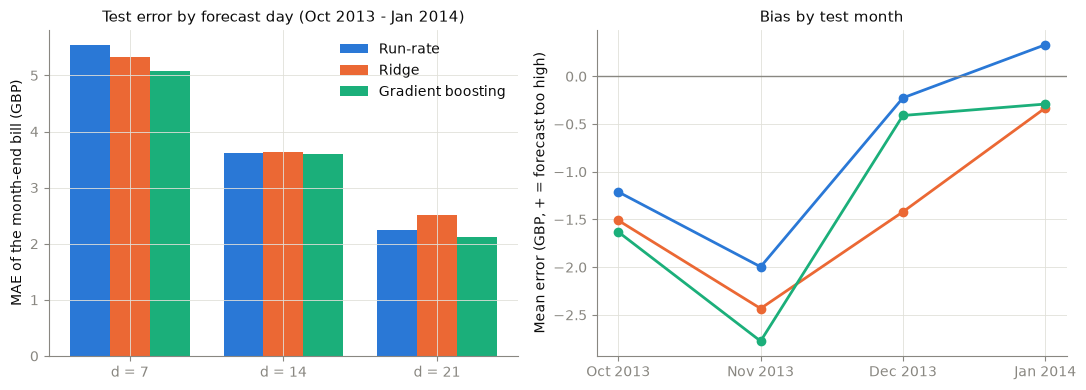

Saved reports/figures/p4_test_error.png


In [20]:
MAIN = ["Run-rate", "Ridge", "Gradient boosting"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
x = np.arange(len(D_VALUES))
w = 0.26
for k, name in enumerate(MAIN):
    vals = test_by_d[test_by_d.model == name].sort_values("d")
    axes[0].bar(x + (k - 1) * w, vals.MAE, w, label=name, color=COLORS[k])
axes[0].set_xticks(x, [f"d = {dv}" for dv in D_VALUES])
axes[0].set_ylabel("MAE of the month-end bill (GBP)")
axes[0].set_title("Test error by forecast day (Oct 2013 - Jan 2014)")
axes[0].legend(frameon=False)
for k, name in enumerate(MAIN):
    vals = test_by_month[test_by_month.model == name].sort_values("month")
    axes[1].plot(vals.month.dt.strftime("%b %Y"), vals.bias, marker="o", label=name, color=COLORS[k])
axes[1].axhline(0, color=MUTED, lw=1)
axes[1].set_ylabel("Mean error (GBP, + = forecast too high)")
axes[1].set_title("Bias by test month")
fig.tight_layout()
save(fig, "p4_test_error.png")

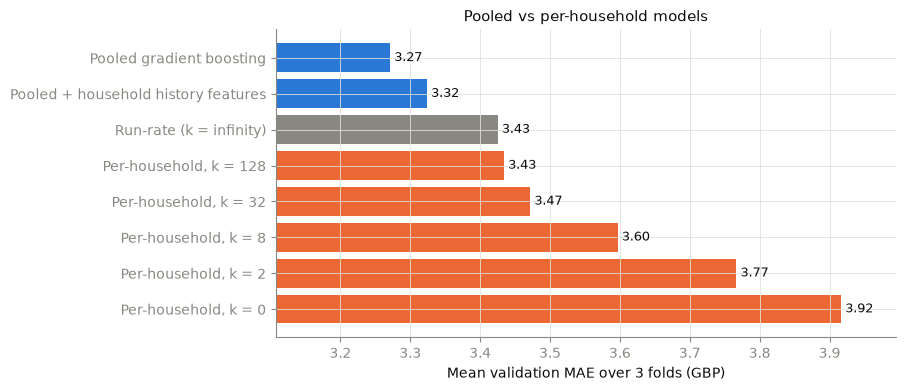

Saved reports/figures/p4_pooled_vs_household.png


In [21]:
fig, ax = plt.subplots(figsize=(8, 4))
t = pooled_vs_hh_table["mean"].sort_values()
colors = [COLORS[0] if "Pooled" in i else COLORS[1] if "Per-household" in i else MUTED for i in t.index]
ax.barh(t.index, t.values, color=colors)
ax.invert_yaxis()
ax.set_xlim(t.min() * 0.95, t.max() * 1.02)
ax.set_xlabel("Mean validation MAE over 3 folds (GBP)")
ax.set_title("Pooled vs per-household models")
for i, v in enumerate(t.values):
    ax.text(v, i, f" {v:.2f}", va="center", fontsize=9, color=INK)
save(fig, "p4_pooled_vs_household.png")

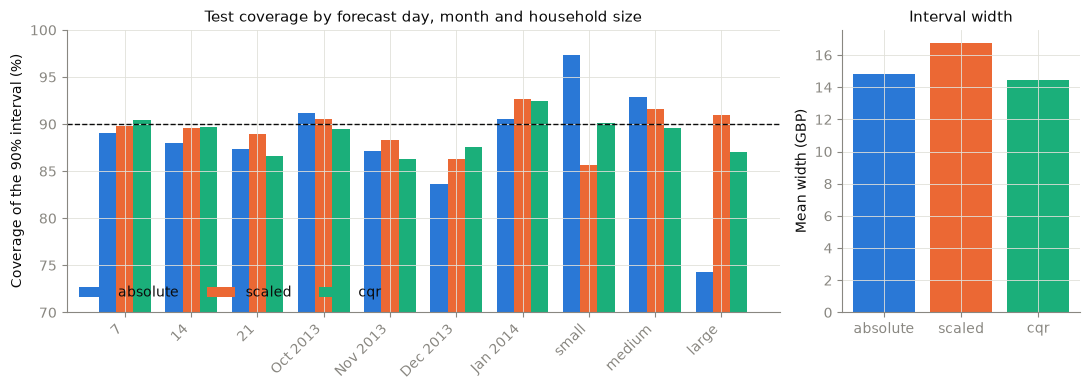

Saved reports/figures/p4_interval_coverage.png


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [3, 1]})
groups = [g for g in iv_test_report.group.unique() if g != "all"]
x = np.arange(len(groups))
for k, method in enumerate(INTERVAL_METHODS):
    r = iv_test_report[iv_test_report.method == method].set_index("group").loc[groups]
    axes[0].bar(x + (k - 1) * w, 100 * r.coverage, w, label=method, color=COLORS[k])
    a = iv_test_report[(iv_test_report.method == method) & (iv_test_report.group == "all")].iloc[0]
    axes[1].bar(k, a["mean width"], color=COLORS[k])
axes[0].axhline(100 * (1 - ALPHA), color=INK, lw=1, ls="--")
axes[0].set_ylim(70, 100)
axes[0].set_xticks(x, [g.split(" = ")[1] for g in groups], rotation=45, ha="right")
axes[0].set_ylabel("Coverage of the 90% interval (%)")
axes[0].set_title("Test coverage by forecast day, month and household size")
axes[0].legend(frameon=False, ncols=3, loc="lower left")
axes[1].set_xticks(range(len(INTERVAL_METHODS)), INTERVAL_METHODS)
axes[1].set_ylabel("Mean width (GBP)")
axes[1].set_title("Interval width")
fig.tight_layout()
save(fig, "p4_interval_coverage.png")

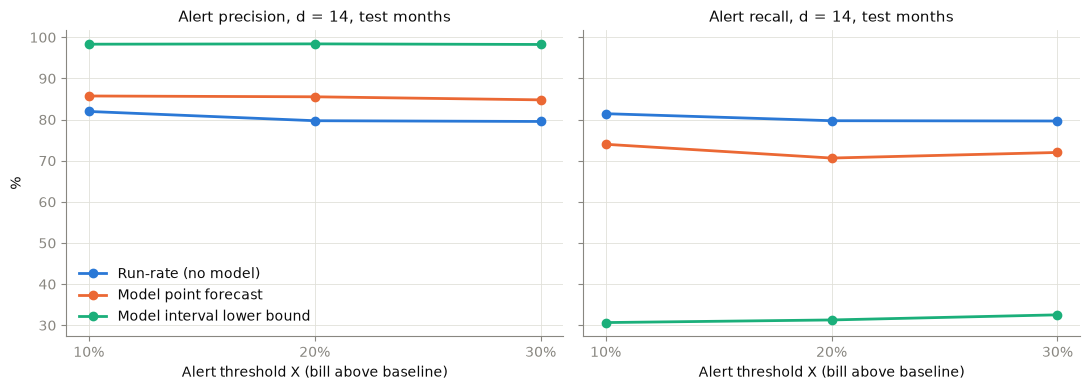

Saved reports/figures/p4_alerts.png


In [23]:
sel = alerts_test[(alerts_test.baseline == ALERT_BASELINE) & (alerts_test.d == FINAL_D)]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, metric in zip(axes, ["precision", "recall"]):
    for k, rule in enumerate(sel.rule.unique()):
        r = sel[sel.rule == rule]
        ax.plot(100 * r.X, 100 * r[metric], marker="o", label=rule, color=COLORS[k])
    ax.set_xticks([100 * x for x in ALERT_X], [f"{100 * x:.0f}%" for x in ALERT_X])
    ax.set_xlabel("Alert threshold X (bill above baseline)")
    ax.set_title(f"Alert {metric}, d = {FINAL_D}, test months")
axes[0].set_ylabel("%")
axes[0].legend(frameon=False)
fig.tight_layout()
save(fig, "p4_alerts.png")

## 11. Saved output and final checks

The test forecasts, intervals and default alerts are saved for the report. Each check counts violations; every count
must be 0, and a failure stops the notebook.

In [24]:
lower, upper = iv_test[INTERVAL_METHOD]
ALERT_SIGNAL = {"Run-rate (no model)": test["runrate_bill_gbp"].to_numpy(),
                "Model point forecast": test_pred["Gradient boosting"], "Model interval lower bound": lower}
base = BASELINE_GBP[ALERT_BASELINE][test_mask].to_numpy()
threshold = base * (1 + ALERT_DEFAULT_X)
predictions = test[["LCLid", "month", "d", "final_bill_gbp", "known_gbp", "runrate_bill_gbp"]].assign(
    ridge_bill_gbp=test_pred["Ridge"],
    gb_bill_gbp=test_pred["Gradient boosting"],
    gb_lower_gbp=lower,
    gb_upper_gbp=upper,
    baseline_gbp=base,
    alert=ALERT_SIGNAL[ALERT_RULE] > threshold,                # NaN baseline compares False: no alert
    overrun=test["final_bill_gbp"].to_numpy() > threshold,
)
con.register("predictions_df", predictions)
con.execute(f"COPY predictions_df TO '{PREDICTIONS_PARQUET}' (FORMAT parquet)")
print(f"Saved {len(predictions):,} rows to {PREDICTIONS_PARQUET.relative_to(ROOT)}")
predictions.head()

Saved 48,321 rows to data/processed/predictions_test.parquet


,LCLid,month,d,final_bill_gbp,known_gbp,runrate_bill_gbp,ridge_bill_gbp,gb_bill_gbp,gb_lower_gbp,gb_upper_gbp,baseline_gbp,alert,overrun
206100,MAC000002,2013-10-01,7,53.806170,10.416319,46.129412,46.438084,45.711643,36.433665,53.122053,40.908061,False,True
206101,MAC000002,2013-10-01,14,53.806170,20.899794,46.278115,46.526524,45.003012,40.157782,49.902390,40.908061,False,True
206102,MAC000002,2013-10-01,21,53.806170,37.908799,55.960607,59.884505,56.487703,48.706209,67.142670,40.908061,True,True
206103,MAC000003,2013-10-01,7,49.354086,11.639358,51.545727,51.578333,54.259050,44.993339,66.746742,79.183658,False,False
206104,MAC000003,2013-10-01,14,49.354086,22.330561,49.446243,49.395898,49.918822,44.833597,58.271513,79.183658,False,False


In [25]:
fold_ends_ok = all(pd.Timestamp(t) < pd.Timestamp(v0) for t, v0, _ in FOLDS)
saved = con.sql(f"SELECT count(*) AS n, count(gb_bill_gbp) AS pred, count(gb_lower_gbp) AS iv FROM '{PREDICTIONS_PARQUET}'").df().iloc[0]
checks = {
    "a fold's training months reach into its validation months": not fold_ends_ok,
    "final training rows from the test months": int((df.month[final_train_mask] >= pd.Timestamp(TEST_START)).sum()),
    "calibration rows from the test months": int((df.month[cal_all] >= pd.Timestamp(TEST_START)).sum()),
    "training + test rows differ from the dataset": abs(int(final_train_mask.sum() + test_mask.sum()) - len(df)),
    "test rows without a point forecast or interval": int(np.isnan(test_pred["Gradient boosting"]).sum()
                                                        + np.isnan(lower).sum() + np.isnan(upper).sum()),
    "intervals with lower bound above upper bound": int((lower > upper).sum()),
    "forecasts below the bill already on the meter": int(sum((test_pred[m] < test.known_gbp.to_numpy() - 1e-9).sum()
                                                             for m in MODELS)),
    "saved prediction rows differ from test rows": abs(int(saved.n) - int(test_mask.sum())),
    "saved rows missing a forecast or interval": int(saved.n - saved.pred) + int(saved.n - saved.iv),
}
for name, bad in checks.items():
    print(f"{'OK  ' if not bad else 'FAIL'} {name}: {bad}")
for name, bad in checks.items():
    assert not bad, name
print(f"\nAll {len(checks)} checks passed.")

OK   a fold's training months reach into its validation months: False
OK   final training rows from the test months: 0
OK   calibration rows from the test months: 0
OK   training + test rows differ from the dataset: 0
OK   test rows without a point forecast or interval: 0
OK   intervals with lower bound above upper bound: 0
OK   forecasts below the bill already on the meter: 0
OK   saved prediction rows differ from test rows: 0
OK   saved rows missing a forecast or interval: 0

All 9 checks passed.


## 12. Conclusions

**What the experiment established**

1. **Final model: pooled histogram gradient boosting on the ratio target.** Test MAE is GBP 3.60 per monthly bill
   (MdAPE 4.2%), vs GBP 3.80 for the run-rate. The 5% gain is statistically clear overall and at d = 7 and 21, but
   not at d = 14. The run-rate is a strong benchmark, and the honest claim is a modest, reliable improvement, not a
   large one.
2. **The target transformation and feature choice did the work, not model complexity.** Predicting the correction to
   the run-rate, with features that compare this month to the household's own recent level, beat raw-kWh targets and
   linear models. Month-of-year features hurt because two years of data teach weather, not seasons.
3. **Pooled beats per-household.** Household-specific history adds nothing on top of the pooled model.
4. **Prediction intervals: CQR, 88.9% coverage on the test months** (target 90%), consistent across forecast days,
   months and household sizes, with a mean width of GBP 14.
5. **Decision layer:**
   - `d` = 14.
   - Baseline = same month last year, else the trailing 3-month mean.
   - Default X = 20%, a household setting.
   - Alert on the run-rate threshold, and show the model's forecast and interval in the message.

   This gives 80% precision and 80% recall on test overruns.

**Limitations**

- The bill is a computed proxy (kWh x 14.228 p/kWh), with no standing charge and no real invoice.
- Standard-tariff households only. Time-of-use households are the stretch goal.
- Only complete household-months were kept in Phase 2. A live system would not know in advance that a month will be
  complete.
- The test window is four autumn/winter months, the hardest season (rising usage, under-forecasting). Coverage and
  error in spring and summer are expected to be better, as folds 2 and 3 suggest.
- About 2 years of data: seasonal effects cannot be learned reliably, and same-month-last-year lags exist only from
  2013.
- Conformal coverage relies on past errors resembling future ones; a very unusual month (a cold snap) can break it.